# Mini-Assigment 3 Math 550

This exercise is a simulation of the Monty-Hall problem. There are 3 doors and one hides the prize. The contestant picks a door. The host, who knows where the prize is, opens a door that is different from the pick and empty. The contestant then either stays with the first pick or switches to the other closed door. We run simulatioin to see what is the long run proportion of winnings with the decision of keep the same door (stay) or switching it (switch).



In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import scipy as sp
from matplotlib import pyplot as plt

# **1. Simulating one game.**

Doors are numbered 1, 2, 3. Each game goes like this:
1. The prize is put behind a random door, and the contestant picks a random door (`np.random.randint`).
2. The host opens a door that is neither the pick nor the prize. If two doors qualify (when the pick is the prize door), the host chooses one at random (`np.random.permutation`).
3. If the contestant switches, the new pick is the only door that is neither the first pick nor the opened door.

The function returns 1 for a win and 0 for a loss.

In [5]:
def play_game(switch):
    doors = [1, 2, 3]
    prize = np.random.randint(low=1, high=4)  # door hiding the prize (high is excluded)
    pick = np.random.randint(low=1, high=4)   # contestant's first pick

    # Doors the host is allowed to open: not the pick, not the prize.
    host_options = [d for d in doors if d != pick and d != prize]
    opened = np.random.permutation(host_options)[0]

    if switch:
        pick = [d for d in doors if d != pick and d != opened][0]

    if pick == prize:
        return 1
    else:
        return 0

In [6]:
# Quick check: 10 games with each strategy.
np.random.seed(12345)  # Setting a seed for reproducibility.
print('stay:  ', [play_game(switch=False) for i in range(10)])
print('switch:', [play_game(switch=True) for i in range(10)])

stay:   [0, 1, 0, 0, 0, 0, 0, 0, 0, 1]
switch: [1, 1, 1, 1, 0, 1, 0, 1, 1, 1]


Now we playing many games with each strategy to see the long run proportion.

In [7]:
np.random.seed(12345)
n = 10000  # number of games per strategy

stay_wins = [play_game(switch=False) for i in range(n)]
switch_wins = [play_game(switch=True) for i in range(n)]

games_df = pd.DataFrame({
    'strategy': ['stay'] * n + ['switch'] * n,
    'win': stay_wins + switch_wins
})
games_df.head(10)

,strategy,win
0,stay,0
1,stay,1
2,stay,0
3,stay,0
4,stay,0
5,stay,0
6,stay,0
7,stay,0
8,stay,0
9,stay,1


##### The win rate of each strategy is the mean of the 0/1 `win` column, computed with groupby + agg.

In [8]:
agg_df = games_df\
    .groupby(['strategy'], as_index=False)[['win']]\
    .agg(games=pd.NamedAgg('win', lambda x: x.count()),
         wins=pd.NamedAgg('win', lambda x: x.sum()),
         win_rate=pd.NamedAgg('win', lambda x: x.mean()))
agg_df

,strategy,games,wins,win_rate
0,stay,10000,3290,0.3290
1,switch,10000,6696,0.6696


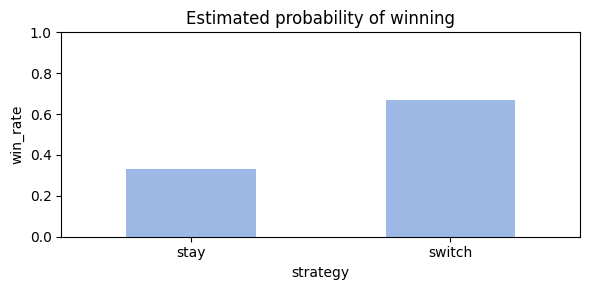

In [9]:
plt.rcParams["figure.figsize"] = [6, 3]
plt.rcParams["figure.autolayout"] = True

ax = sns.barplot(data=agg_df, x='strategy', y='win_rate', width=.5, alpha=.7, color='cornflowerblue')
ax.set_ylim(0, 1)
ax.set_title('Estimated probability of winning');

One run gives one estimate of each win rate. Now we repeat the experiment many times to get a sample of averages. Each experiment plays 500 games, and we run 1000 experiments per strategy. This is to see if there is a lot of variability between the repetitions, so it is to verify if we can conclude that the probability of the stay strategy is 1/3 and the probability of the switch srategy is 2/3.

In [10]:
np.random.seed(12345)
n = 500             # games per experiment
n_experiments = 1000

stay_rates = []
switch_rates = []
for i in range(n_experiments):
    stay_rates.append(np.mean([play_game(switch=False) for j in range(n)]))
    switch_rates.append(np.mean([play_game(switch=True) for j in range(n)]))

rates_df = pd.DataFrame({
    'strategy': ['stay'] * n_experiments + ['switch'] * n_experiments,
    'win_rate': stay_rates + switch_rates
})
rates_df.groupby('strategy')['win_rate'].agg(['mean', 'std', 'min', 'max'])

,mean,std,min,max
strategy,,,,
stay,0.332948,0.021377,0.256,0.400
switch,0.666366,0.020670,0.602,0.742


To test the probability we can consider the null hypothesis $H_{0}: p=p_0$ and $H_{a}: p>p_0$, with $p_0=1/3$ for the stay and equal $2/3$ for the switch.

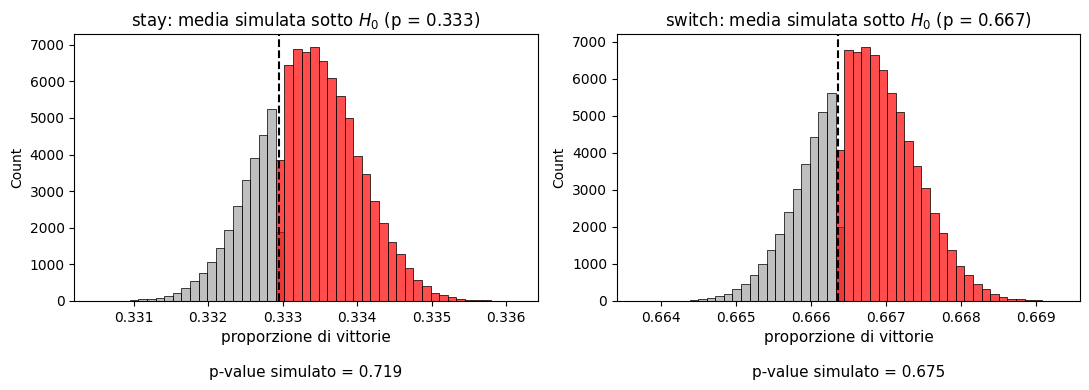

In [11]:

# simnulated p-value
B = 100000
total_games = n * n_experiments

def simulated_p_value(rates, p0):
    mu = np.mean(rates)                                                # observed statistics
    null_means = np.random.binomial(n=total_games, p=p0, size=B) / total_games  
    p_value = np.mean(null_means >= mu)                                # cases >= mu
    return mu, p_value, null_means

tests = {'stay': (stay_rates, 1/3), 'switch': (switch_rates, 2/3)}

# Istograms of the simulated distribution under H0
plt.rcParams["figure.figsize"] = [11, 4]
plt.rcParams["figure.autolayout"] = True
fig, ax = plt.subplots(1, 2)

np.random.seed(12345)
for k, (name, (rates, p0)) in enumerate(tests.items()):
    mu, p_value, null_means = simulated_p_value(rates, p0)

    bins = np.linspace(null_means.min(), null_means.max(), 50)
    sns.histplot(x=null_means[null_means < mu], bins=bins, stat='count', color='grey', alpha=.5, ax=ax[k])
    sns.histplot(x=null_means[null_means >= mu], bins=bins, stat='count', color='red', alpha=.7, ax=ax[k])
    ax[k].axvline(mu, color='black', linestyle='--')
    ax[k].set_title(f'{name}: media simulata sotto $H_0$ (p = {p0:.3f})')
    ax[k].set_xlabel(f'proporzione di vittorie\n\np-value simulato = {p_value:.3f}', fontsize=11)

plt.show()

Both the p-values are way larger than 0.5 (The tipical confidence rate) so we can in both case accept the null hypothesis and conclude that the long run proportion of winning is 1/3 wit the stay strategy and 2/3 with the switch strategy.

Moreover, by the CLT, each win rate is approximately normal with mean $p$ and standard deviation $\sqrt{p(1-p)/n}$. Now we compute the p-value using the theory baseds approach with the z-score and we notice that they are basically the same.

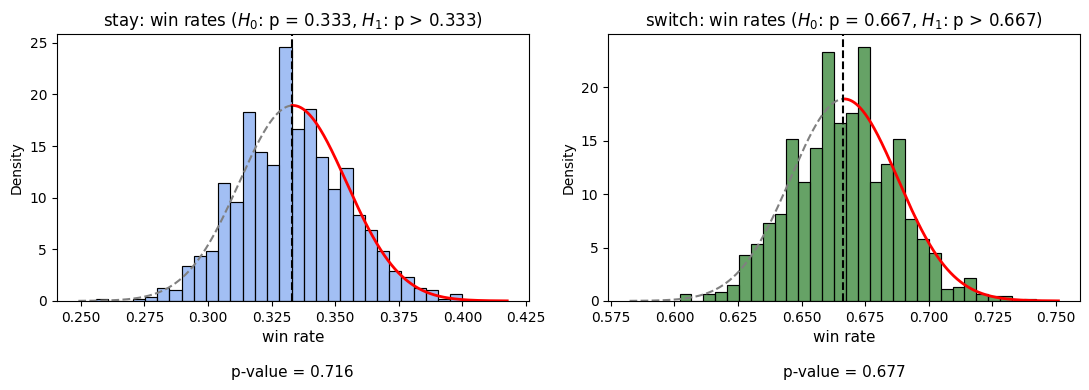

In [12]:

def one_sided_test(rates, p0):
    rates = np.array(rates)
    mu = rates.mean()                          # win rate mean
    sd = rates.std(ddof=1)                     # sample sd 
    sigma = sd / np.sqrt(len(rates))           # population sd 
    z = (mu - p0) / sigma                      # z-score
    p_value = 1 - sp.stats.norm.cdf(x=z, loc=0, scale=1)  # P(Z >= z)
    return mu, p_value

tests = {'stay': (stay_rates, 1/3), 'switch': (switch_rates, 2/3)}

# Istograms with p-value
plt.rcParams["figure.figsize"] = [11, 4]
plt.rcParams["figure.autolayout"] = True
fig, ax = plt.subplots(1, 2)

colors = {'stay': 'cornflowerblue', 'switch': 'darkgreen'}

for k, (name, (rates, p0)) in enumerate(tests.items()):
    mu, p_value = one_sided_test(rates, p0)

    sd_one = np.sqrt(p0 * (1 - p0) / n)
    x_values = p0 + np.arange(-4 * sd_one, 4 * sd_one, .0001)
    y_values = sp.stats.norm.pdf(x=x_values, loc=p0, scale=sd_one)
    right = x_values >= mu

    sns.histplot(x=rates, stat='density', bins=30, alpha=.6, color=colors[name], ax=ax[k])
    sns.lineplot(x=x_values[~right], y=y_values[~right], color='grey', linestyle='--', ax=ax[k])
    sns.lineplot(x=x_values[right], y=y_values[right], color='red', linewidth=2, ax=ax[k])
    ax[k].axvline(mu, color='black', linestyle='--')
    ax[k].set_title(f'{name}: win rates ($H_0$: p = {p0:.3f}, $H_1$: p > {p0:.3f})')
    ax[k].set_xlabel(f'win rate\n\np-value = {p_value:.3f}', fontsize=11)

plt.show()

In conclusion switching wins about 2/3 of the time and staying about 1/3, so the best strategy is to always switch.

Moreopver we compare the two strategies directly to find out which one is better. From this point it is clear that the switch strategy is the best one but we try to run another experiment considering as $H_0$: $\mu_{switch} = \mu_{stay}$, i.e. both strategies win, on average, equally often and as
$H_1$: $\mu_{switch} \neq \mu_{stay}$ (two-sided test).

We use the t-statistic to run the experiment and we consider that if the p-value is less than $\alpha = 5\%$ we reject $H_0$

$$
t = \frac{\bar x_{switch} - \bar x_{stay}}{s_{\bar\Delta}}, \qquad s_{\bar\Delta} = \sqrt{\frac{s^2_{switch}}{n_{switch}} + \frac{s^2_{stay}}{n_{stay}}}
$$

$$
\text{p-value} = \mathbb{P}\left(|T| \geq |t| \,\big|\, H_0\right).
$$


In [13]:
x_A, x_B = np.array(switch_rates), np.array(stay_rates)

mu_A, mu_B = x_A.mean(), x_B.mean()                    # sample means
sd_A, sd_B = x_A.std(ddof=1), x_B.std(ddof=1)          # sample sds
sd_delta = np.sqrt(sd_A**2/len(x_A) + sd_B**2/len(x_B))
t = (mu_A - mu_B) / sd_delta                           # t-score
p_value = 2 - 2 * sp.stats.t.cdf(x=abs(t), loc=0, scale=1, df=len(x_A) + len(x_B) - 2)

print(f'switch mean = {mu_A:.4f}, stay mean = {mu_B:.4f}')
print(f't = {t:.2f}, p-value = {p_value:.3g}')


res = sp.stats.ttest_ind(a=switch_rates, b=stay_rates, equal_var=False, alternative='two-sided')
res

switch mean = 0.6664, stay mean = 0.3329
t = 354.58, p-value = 0


TtestResult(statistic=np.float64(354.5765145179321), pvalue=np.float64(0.0), df=np.float64(1995.7433437429406))

Also here the p-value is almost zero so it is clear that the tw strategies have different winning probability and that the switch one is better than the stay one.